<a href="https://colab.research.google.com/github/AlvinManoj05/Transfer_Learning-_for_Image_Classification./blob/main/Transfer_Learning_for_Image_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

if tf.config.list_physical_devices('GPU'):
    print("GPU is being used!")
    print(tf.config.list_physical_devices('GPU')[0])
else:
    print("WARNING: GPU not detected.")

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU is being used!
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


# Import Libraries

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from tensorflow.keras.optimizers import AdamW

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

#Set Random Seeds

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


# Data Preparation

In [3]:
# Load CIFAR-10
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

print("Training data:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test data:", X_test.shape)
print("Test labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 847s 5us/step
Training data: (50000, 32, 32, 3)
Training labels: (50000, 1)
Test data: (10000, 32, 32, 3)
Test labels: (10000, 1)


In [4]:
# Create Train/Validation Split

X_train = X_train[:45000]
y_train = y_train[:45000]

X_val = X_train[45000:]
y_val = y_train[45000:]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (45000, 32, 32, 3)
Validation: (0, 32, 32, 3)
Testing: (10000, 32, 32, 3)


In [5]:
# Class Names

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

num_classes = len(class_names)
print("Number of classes:", num_classes)

Number of classes: 10


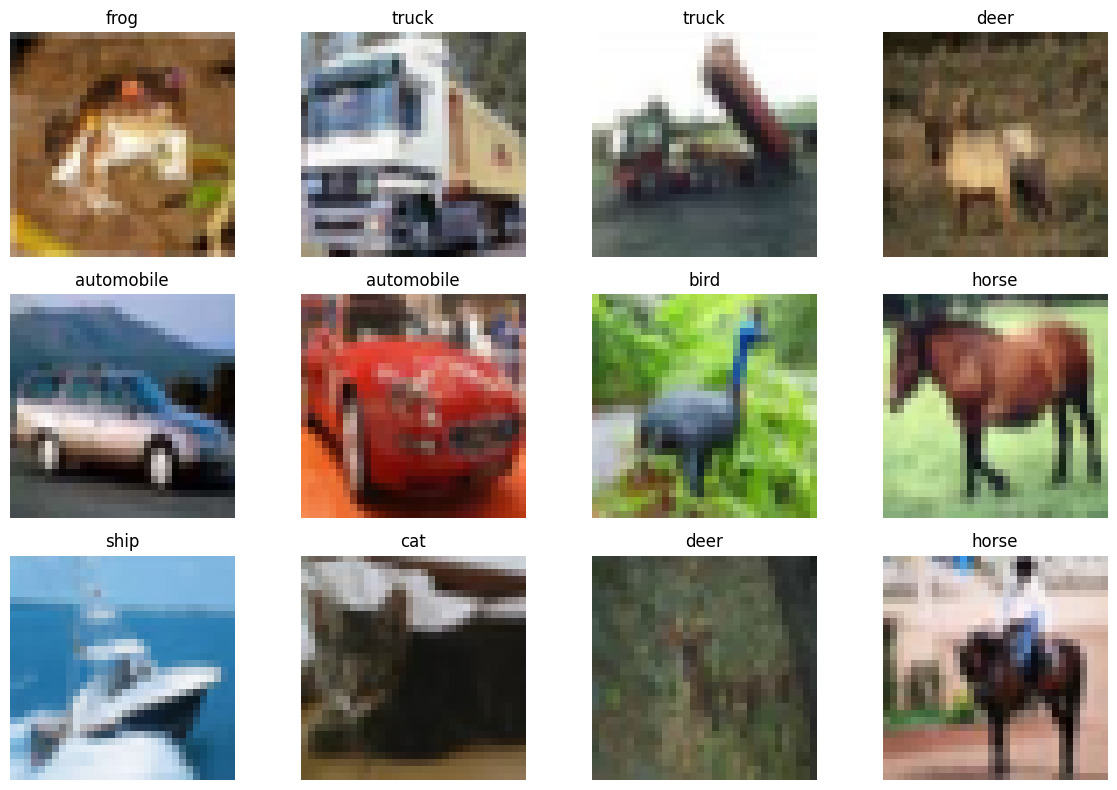

In [6]:
plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Data Augmentation

In [7]:
IMG_SIZE = 224
BATCH_SIZE = 64

data_segmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.1),

    layers.RandomCrop(
        height=200,
        width=200
    ),

    layers.Resizing(
        IMG_SIZE,
        IMG_SIZE
    )
])

# Data Pipeline

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_train(image, label):
    image = tf.cast(image, tf.float32)

    image = data_augmentation(image)

    image = preprocess_input(image)

    return image, label


def preprocess_test(image, label):
    image = tf.cast(image, tf.float32)

    image = tf.image.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )

    image = preprocess_input(image)

    return image, label

In [9]:
def preprocess_train(image, label):
    image = tf.cast(image, tf.float32)
    image = data_augmentation(image)
    image = preprocess_input(image)
    return image, label

In [10]:
import tensorflow as tf
from tensorflow.keras import layers

IMG_SIZE = 224
BATCH_SIZE = 64

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomCrop(200, 200),
    layers.Resizing(IMG_SIZE, IMG_SIZE)
], name="data_augmentation")

print("Data augmentation created successfully!")

Data augmentation created successfully!


In [11]:
from tensorflow.keras.applications.resnet50 import preprocess_input

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_train(image, label):
    image = tf.cast(image, tf.float32)

    image = data_augmentation(image)

    image = preprocess_input(image)

    return image, label


def preprocess_test(image, label):
    image = tf.cast(image, tf.float32)

    image = tf.image.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )

    image = preprocess_input(image)

    return image, label

# TensorFlow Datasets

In [12]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

train_ds = (
    train_ds
    .shuffle(10000)
    .map(preprocess_train, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .map(preprocess_test, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds
    .map(preprocess_test, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Datasets created successfully!")

Datasets created successfully!


Load Pretrained ResNet50

In [13]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

print("Total layers:", len(base_model.layers))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Total layers: 175


In [14]:
include_top=False

# Build Required Classifier Head

In [15]:
l2_reg = regularizers.l2(1e-4)

inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3)
)

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    512,
    kernel_initializer="he_normal",
    kernel_regularizer=l2_reg
)(x)

x = layers.BatchNormalization()(x)

x = layers.ReLU()(x)

x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax",
    kernel_initializer="he_normal",
    kernel_regularizer=l2_reg
)(x)

model = models.Model(
    inputs,
    outputs
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,643,978 (94.01 MB)

 Trainable params: 1,055,242 (4.03 MB)

 Non-trainable params: 23,588,736 (89.98 MB)

In [16]:
kernel_initializer="he_normal"

In [17]:
kernel_regularizer=regularizers.l2(1e-4)

# Feature Extraction

In [18]:
# Compile Model

model.compile(
    optimizer=AdamW(
        learning_rate=1e-3,
        weight_decay=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
#Callbacks

checkpoint_path = "best_resnet50_feature_extraction.keras"

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [ ]:
# Train Feature Extraction Model

EPOCHS_FEATURE = 20

history_feature = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FEATURE,
    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ]
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - accuracy: 0.7252 - loss: 0.9265

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()
/usr/local/lib/python3.13/dist-packages/keras/src/callbacks/early_stopping.py:99: UserWarning: Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: accuracy,loss
  current = self.get_monitor_value(logs)
/usr/local/lib/python3.13/dist-packages/keras/src/callbacks/callback_list.py:171: UserWarning: Learning rate reduction is conditioned on metric `val_loss` which is not available. Available metrics are: accuracy,loss,learning_rate.
  callback.on_epoch_end(epoch, logs)
/usr/local/lib/python3.13/dist-packages/keras/src/callbacks/model_checkpoint.py:276: UserWarning: Can save best model only with val_loss av


Epoch 1: finished saving model to best_resnet50_feature_extraction.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 252s 334ms/step - accuracy: 0.7724 - loss: 0.7781 - learning_rate: 0.0010
Epoch 2/20
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - accuracy: 0.8196 - loss: 0.6386
Epoch 2: finished saving model to best_resnet50_feature_extraction.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 262s 372ms/step - accuracy: 0.8195 - loss: 0.6403 - learning_rate: 0.0010
Epoch 3/20
674/704 ━━━━━━━━━━━━━━━━━━━━ 10s 334ms/step - accuracy: 0.8334 - loss: 0.6033

In [ ]:
# Evaluate Feature Extraction

feature_results = model.evaluate(
    test_ds,
    verbose=1
)

print(
    "Feature Extraction Test Loss:",
    feature_results[0]
)

print(
    "Feature Extraction Test Accuracy:",
    feature_results[1]
)

In [ ]:
feature_test_loss = feature_results[0]
feature_test_accuracy = feature_results[1]

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_feature.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_feature.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Feature Extraction: Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_feature.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_feature.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Feature Extraction: Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
N = 30

base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

print("Trainable layers:")

for layer in base_model.layers:
    if layer.trainable:
        print(layer.name)

In [ ]:
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [ ]:
model.compile(
    optimizer=AdamW(
        learning_rate=1e-5,
        weight_decay=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
checkpoint_finetune = ModelCheckpoint(
    "best_resnet50_finetuned.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stopping_finetune = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_finetune = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-8,
    verbose=1
)

In [ ]:
EPOCHS_FINETUNE = 15

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINETUNE,
    callbacks=[
        early_stopping_finetune,
        reduce_lr_finetune,
        checkpoint_finetune
    ]
)